In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/weather_daily.csv", parse_dates=["time"])
print(df.shape)
df.head()

(8768, 9)


,city,time,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max,wind_gusts_10m_max
0,London,2023-01-01,11.9,7.9,4.0,4.0,0.0,31.4,63.7
1,London,2023-01-02,8.3,0.9,0.2,0.2,0.0,15.5,25.9
2,London,2023-01-03,12.4,2.2,3.2,3.2,0.0,37.4,62.6
3,London,2023-01-04,13.1,9.9,0.9,0.9,0.0,35.9,60.1
4,London,2023-01-05,12.9,7.7,0.1,0.1,0.0,31.5,50.4


In [2]:
df.describe().round(1)

,time,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max,wind_gusts_10m_max
count,8768,8768.0,8768.0,8768.0,8768.0,8768.0,8768.0,8768.0
mean,2024-07-01 12:00:00,14.0,7.2,2.8,2.7,0.0,21.1,42.0
min,2023-01-01 00:00:00,-2.1,-7.8,0.0,0.0,0.0,2.7,7.2
25%,2023-10-01 18:00:00,9.8,3.8,0.0,0.0,0.0,15.2,31.3
50%,2024-07-01 12:00:00,13.8,7.5,0.6,0.6,0.0,20.0,40.0
75%,2025-04-01 06:00:00,18.0,10.9,3.5,3.5,0.0,25.9,50.4
max,2025-12-31 00:00:00,33.6,22.8,57.7,57.7,13.2,61.2,121.3
std,NaN,5.8,4.8,5.0,4.9,0.4,8.1,15.0


Matplotlib is building the font cache; this may take a moment.


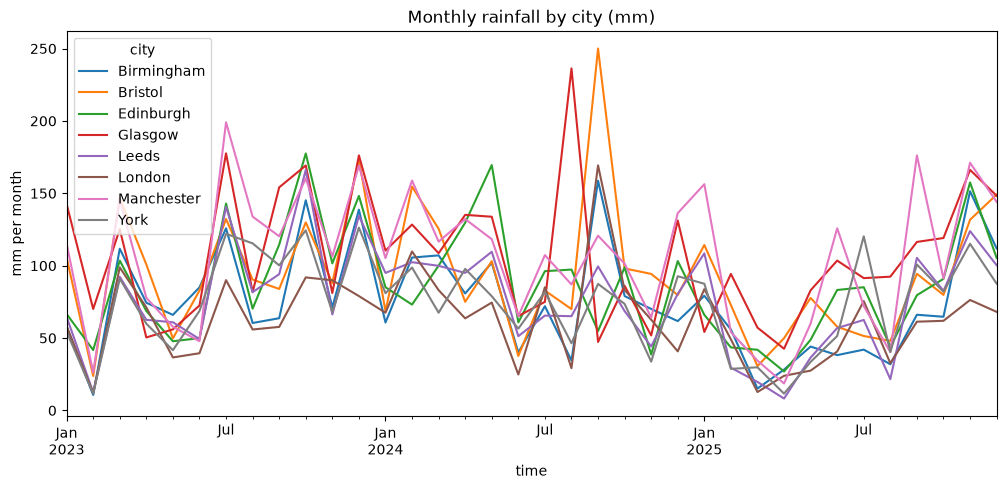

In [3]:
import matplotlib.pyplot as plt

monthly = (df.set_index("time")
             .groupby("city")["precipitation_sum"]
             .resample("MS").sum()
             .unstack(0))

monthly.plot(figsize=(12, 5), title="Monthly rainfall by city (mm)")
plt.ylabel("mm per month")
plt.show()
